HomeWork 4

# Data Preparation
- Date: 2022-01-01 00:00 ~ 2025-12-31 23:00
- Station: 
    - \# of Station: 13
    - Dublin Airport;
    - Phoenix Park; Casement; Dunsany;
    - Mullingar; Ballyhaise; Oak Park; Johnstown Castle 2; 
    - Cork Airport; Finner; Knock Airport; Malin Head; Shannon Airport.
- Variables:
    - `temp`: Air Temperature (C)
    - `msl`: Mean Sea Level Pressure (hPa)
    - `rhum`: Relative Humidity (%)
    - `rain`: Precipitation Amount (mm)
$$X\in\mathbb{R}^{43824\times13\times4}$$

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

import copy
from urllib.request import urlretrieve

import geopandas as gpd
import networkx as nx
from shapely.geometry import Point

import torch
from torch import nn
from torch.nn import functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv

d:\Study\Code\Python\AI for Weather and Climate\AIfW-Presentation-4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Study\Code\Python\AI for Weather and Climate\AIfW-Presentation-4\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# configuration
DATA_DIR = Path("DATA/processed")
FEATURES = ["temp", "msl", "rhum", "rain"]
TARGET_STATION = "Dublin Airport 532"
LOOKBACK = 24               # hours of historical observations
HORIZON = 6                 # direct forecast at t + 6 hours
K = 3                       # geographical nearest neighbours
TRAIN_END = pd.Timestamp("2024-01-01", tz="UTC")
VAL_END = pd.Timestamp("2025-01-01", tz="UTC")
SEED = 2026

# Load each source once; retain X_raw as the single raw-data array
X_raw = np.load(DATA_DIR / "weather_tensor.npy").astype(np.float32)
stations = pd.read_csv(DATA_DIR / "station_order.csv")
metadata = pd.read_csv(DATA_DIR / "station_metadata.csv")
timestamps = pd.to_datetime(
    pd.read_csv(DATA_DIR / "timestamps.csv")["date"], utc=True
)

T, N, n_features = X_raw.shape
assert n_features == len(FEATURES), "Unexpected feature order/number"
assert N == len(stations) and T == len(timestamps), "Data dimensions mismatch"
assert np.isfinite(X_raw).all(), "Missing/invalid values found in weather tensor"
assert (timestamps.diff().dropna() == pd.Timedelta(hours=1)).all(),     "Time points are not consecutive UTC hours"

# This merge also fixes the order of graph nodes to the tensor's station axis
meta = stations.merge(metadata, on="station", how="left", validate="one_to_one")
assert meta["station"].tolist() == stations["station"].tolist()
assert meta[["latitude", "longitude"]].notna().all().all(),     "Station coordinates are incomplete"

target_idx = stations["station"].tolist().index(TARGET_STATION)

missing_pct = pd.DataFrame(
    np.isnan(X_raw).mean(axis=0) * 100,
    index=stations["station"],
    columns=FEATURES,
)
print(f"Raw data: {X_raw.shape}, {timestamps.iloc[0]} to {timestamps.iloc[-1]}")
print("\nMissing rates (%):\n", missing_pct.round(2).to_string())
print("\nStation coordinates:\n", meta[["station", "latitude", "longitude"]].to_string(index=False))
print("\nPhysical ranges:")
for i, name in enumerate(FEATURES):
    values = X_raw[:, :, i]
    print(f"  {name}: {values.min():.2f} to {values.max():.2f}")
print("Quality note: keep_111 preserves airport observations flagged for investigation.")


Raw data: (35064, 13, 4), 2022-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00

Missing rates (%):
                          temp  msl  rhum  rain
station                                       
Ballyhaise 675            0.0  0.0   0.0   0.0
Casement 3723             0.0  0.0   0.0   0.0
Cork Airport 3904         0.0  0.0   0.0   0.0
Dublin Airport 532        0.0  0.0   0.0   0.0
Dunsany 1375              0.0  0.0   0.0   0.0
Finner 2075               0.0  0.0   0.0   0.0
Johnstown Castle 2 1775   0.0  0.0   0.0   0.0
Knock Airport 4935        0.0  0.0   0.0   0.0
Malin Head 1575           0.0  0.0   0.0   0.0
Mullingar 875             0.0  0.0   0.0   0.0
Oak Park 375              0.0  0.0   0.0   0.0
Phoenix Park 175          0.0  0.0   0.0   0.0
Shannon Airport 518       0.0  0.0   0.0   0.0

Station coordinates:
                 station  latitude  longitude
         Ballyhaise 675    54.051     -7.310
          Casement 3723    53.306     -6.439
      Cork Airport 3904    51.847  

# Graph Construction

3-NN Graph

Graph: 13 nodes, 27 undirected edges, connected=True
PyG edge_index: (2, 54)


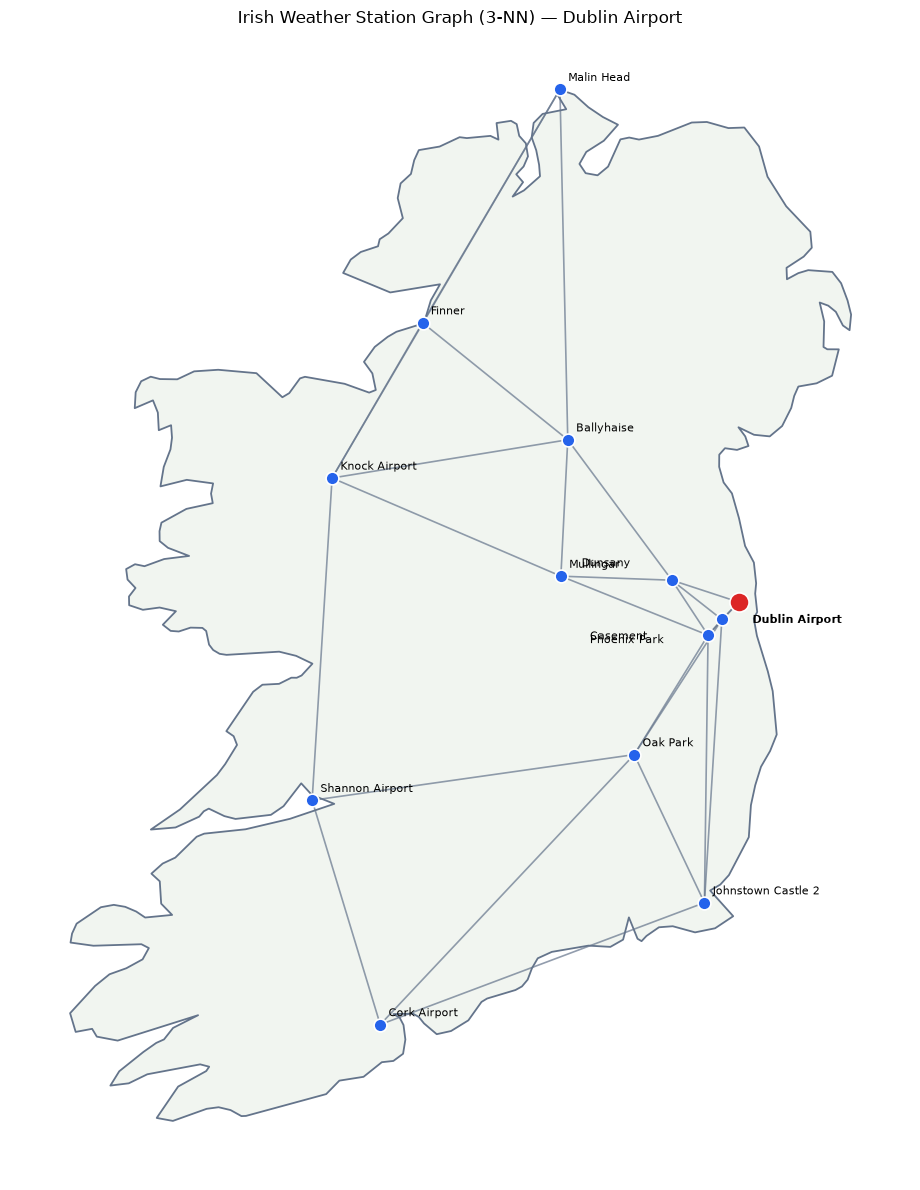


Shortest paths from Dublin Airport:
Ballyhaise 675              : 2 hops
Casement 3723               : 1 hops
Cork Airport 3904           : 3 hops
Dublin Airport 532          : 0 hops
Dunsany 1375                : 1 hops
Finner 2075                 : 3 hops
Johnstown Castle 2 1775     : 2 hops
Knock Airport 4935          : 3 hops
Malin Head 1575             : 3 hops
Mullingar 875               : 2 hops
Oak Park 375                : 2 hops
Phoenix Park 175            : 1 hops
Shannon Airport 518         : 3 hops


In [3]:
# Haversine distance (km); graph construction uses the shared meta order
coords = np.radians(meta[["latitude", "longitude"]].to_numpy())
lat, lon = coords[:, 0], coords[:, 1]
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = (np.sin(dlat / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# Symmetrise the 3-NN graph; every undirected edge becomes two PyG edges
knn_dist = dist.copy()
np.fill_diagonal(knn_dist, np.inf)
neighbours = np.argsort(knn_dist, axis=1)[:, :K]
G = nx.Graph()
G.add_nodes_from(range(N))
for i in range(N):
    G.add_edges_from((i, int(j)) for j in neighbours[i])

edge_pairs = [(a, b) for i, j in G.edges() for a, b in ((i, j), (j, i))]
edge_index = torch.as_tensor(np.array(edge_pairs, dtype=np.int64).T).contiguous()
np.save(DATA_DIR / "edge_index.npy", edge_index.numpy())
print(f"Graph: {N} nodes, {G.number_of_edges()} undirected edges, "
      f"connected={nx.is_connected(G)}")
print("PyG edge_index:", tuple(edge_index.shape))

# Load the Ireland coastline (cached after first run), project to Irish metres
map_file = DATA_DIR / "ne_50m_land.geojson"
map_url = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
    "master/geojson/ne_50m_land.geojson"
)
if not map_file.exists():
    urlretrieve(map_url, map_file)
land = gpd.read_file(map_file).to_crs("EPSG:4326").explode(index_parts=False)
ireland = land.loc[land.geometry.covers(Point(-8, 53.5))].to_crs("EPSG:2157")
if ireland.empty:
    raise ValueError("Could not find the island of Ireland in the coastline file")

gdf = gpd.GeoDataFrame(
    meta.copy(),
    geometry=gpd.points_from_xy(meta["longitude"], meta["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:2157")
pos = {i: (p.x, p.y) for i, p in enumerate(gdf.geometry)}

fig, ax = plt.subplots(figsize=(10, 12))
ireland.plot(ax=ax, facecolor="#F1F5F0", edgecolor="#64748B", linewidth=1.3)
for i, j in G.edges():
    ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]],
            color="#64748B", linewidth=1.2, alpha=0.7, zorder=1)

label_offsets = {
    "Dublin Airport 532": (10, -15),
    "Phoenix Park 175": (-95, -17),
    "Casement 3723": (-85, -3),
    "Dunsany 1375": (-65, 10),
}
for i, row in gdf.iterrows():
    is_target = i == target_idx
    p = row.geometry
    ax.scatter(p.x, p.y, s=190 if is_target else 85,
               color="#DC2626" if is_target else "#2563EB",
               edgecolors="white", linewidth=1.2, zorder=3)
    offset = label_offsets.get(row["station"], (6, 6))
    ax.annotate(row["station"].rsplit(" ", 1)[0], (p.x, p.y),
                xytext=offset, textcoords="offset points", fontsize=8,
                fontweight="bold" if is_target else "normal", zorder=4)

xmin, ymin, xmax, ymax = ireland.total_bounds
ax.set(xlim=(xmin - 25000, xmax + 25000),
       ylim=(ymin - 25000, ymax + 25000),
       title=f"Irish Weather Station Graph ({K}-NN) — Dublin Airport")
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.savefig(DATA_DIR / f"irish_station_graph_{K}nn.png", dpi=300, bbox_inches="tight")
plt.show()

hops = nx.single_source_shortest_path_length(G, target_idx)
print("\nShortest paths from Dublin Airport:")
for i, station in enumerate(stations["station"]):
    print(f"{station:28s}: {hops.get(i, 'Disconnected')} hops")


In [4]:
# Direct h-hour-ahead forecasting: observations through t -> target at t + HORIZON
# Fit feature statistics using TRAINING HOURS ONLY (no future information).
train_hours = timestamps < TRAIN_END
feature_mean = X_raw[train_hours.to_numpy()].mean(axis=(0, 1))
feature_std = X_raw[train_hours.to_numpy()].std(axis=(0, 1))
feature_std = np.where(feature_std < 1e-8, 1.0, feature_std)
X_scaled = (X_raw - feature_mean) / feature_std

n_samples = T - LOOKBACK - HORIZON + 1
assert n_samples > 0
X_samples = np.empty((n_samples, N, LOOKBACK * n_features), dtype=np.float32)
for row, t in enumerate(range(LOOKBACK - 1, T - HORIZON)):
    window = X_scaled[t - LOOKBACK + 1:t + 1]       # [24, 13, 4]
    X_samples[row] = window.transpose(1, 0, 2).reshape(N, -1)

# All three arrays refer to the SAME target timestamps.
# Persistence uses T_t; both GCNs will forecast the observed T_(t+h).
origin_times = pd.DatetimeIndex(timestamps.iloc[LOOKBACK - 1:T - HORIZON])
target_times = pd.DatetimeIndex(timestamps.iloc[LOOKBACK - 1 + HORIZON:])
Y_samples = X_raw[LOOKBACK - 1 + HORIZON:, target_idx, FEATURES.index("temp")]
P_samples = X_raw[LOOKBACK - 1:T - HORIZON, target_idx, FEATURES.index("temp")]
assert len(X_samples) == len(Y_samples) == len(P_samples) == len(target_times)
assert ((target_times - origin_times) == pd.Timedelta(hours=HORIZON)).all()

# ONE chronological split shared by persistence, 2-layer GCN and 3-layer GCN
train_mask = target_times < TRAIN_END
val_mask = (target_times >= TRAIN_END) & (target_times < VAL_END)
test_mask = target_times >= VAL_END

X_train, Y_train = X_samples[train_mask], Y_samples[train_mask]
X_val,   Y_val   = X_samples[val_mask],   Y_samples[val_mask]
X_test,  Y_test  = X_samples[test_mask],  Y_samples[test_mask]
P_test = P_samples[test_mask] # Persistence
test_times = target_times[test_mask]

# Target scaling is also fitted on the training set only.
y_mean, y_std = float(Y_train.mean()), float(Y_train.std())
assert y_std > 0
Y_train_scaled = ((Y_train - y_mean) / y_std).astype(np.float32)
Y_val_scaled   = ((Y_val - y_mean) / y_std).astype(np.float32)

print(f"Forecast: {LOOKBACK} past hours -> t + {HORIZON} hours, target={TARGET_STATION}")
print("Raw:", X_raw.shape, "| Samples:", X_samples.shape)
print("Training:",   X_train.shape, Y_train.shape)
print("Validation:", X_val.shape,   Y_val.shape)
print("Testing:",    X_test.shape,  Y_test.shape)
print("Test period:", test_times[0], "to", test_times[-1])


Forecast: 24 past hours -> t + 6 hours, target=Dublin Airport 532
Raw: (35064, 13, 4) | Samples: (35035, 13, 96)
Training: (17491, 13, 96) (17491,)
Validation: (8784, 13, 96) (8784,)
Testing: (8760, 13, 96) (8760,)
Test period: 2025-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00


# Persistence benchmark
- $\hat T_{t+h}=T_t$

In [5]:
mae_persistence =  np.mean(np.abs(Y_test - P_test))
rmse_persistence = np.sqrt(np.mean((Y_test - P_test)**2))

print("\nPersistence Benchmark:")
print(f"MAE:  {mae_persistence:.4f} °C")
print(f"RMSE: {rmse_persistence:.4f} °C")


Persistence Benchmark:
MAE:  2.5112 °C
RMSE: 3.3900 °C


# 2-layer GCN

$$H^{(l+1)}=\sigma\left(\tilde D^{-1/2}\tilde A\tilde D^{-1/2}H^{(l)}W^{(l)}\right)$$

In [6]:

# ============================================================
# 1. Configuration
# ============================================================

BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 100
PATIENCE = 10
DROPOUT = 0.1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reuse the existing graph
base_edges = edge_index.cpu()


# ============================================================
# 2. PyG Datasets
# ============================================================

def make_loader(X, Y=None, shuffle=False):
    graphs = []

    for i in range(len(X)):
        data = Data(
            x=torch.as_tensor(X[i], dtype=torch.float32),
            edge_index=base_edges
        )

        if Y is not None:
            data.y = torch.tensor([Y[i]], dtype=torch.float32)

        graphs.append(data)

    return DataLoader(
        graphs, batch_size=BATCH_SIZE, shuffle=shuffle
    )


train_loader = make_loader(X_train, Y_train_scaled, True)
val_loader = make_loader(X_val, Y_val_scaled)
test_loader = make_loader(X_test)


# ============================================================
# 3. GCN Model
# ============================================================

class WeatherGCN(nn.Module):

    def __init__(self, hidden_dims):
        super().__init__()

        dims = [X_train.shape[-1]] + hidden_dims

        self.convs = nn.ModuleList([
            GCNConv(dims[i], dims[i + 1])
            for i in range(len(hidden_dims))
        ])

        self.head = nn.Linear(hidden_dims[-1], 1)

    def forward(self, data):
        x = data.x

        for i, conv in enumerate(self.convs):
            x = F.relu(conv(x, data.edge_index))

            if i < len(self.convs) - 1:
                x = F.dropout(
                    x, p=DROPOUT, training=self.training
                )

        # One forecast for each graph's Dublin Airport node
        return self.head(x).reshape(-1, N)[:, target_idx]


# ============================================================
# 4. One Training / Validation Epoch
# ============================================================

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0

    for batch in loader:
        batch = batch.to(device)

        with torch.set_grad_enabled(training):
            pred = model(batch)
            loss = F.mse_loss(pred, batch.y.view(-1))

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * batch.num_graphs

    return total_loss / len(loader.dataset)


In [7]:
architectures = {
    "2-layer GCN": [64, 32],
    "3-layer GCN": [64, 64, 32]
}
trained = {}

for name, hidden_dims in architectures.items():

    torch.manual_seed(SEED)
    np.random.seed(SEED)

    model = WeatherGCN(hidden_dims).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {"train_mse": [], "val_mse": []}
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience = 0

    print(f"\nTraining {name}")

    for epoch in range(1, MAX_EPOCHS + 1):

        train_loss = run_epoch(model, train_loader, optimizer)
        val_loss = run_epoch(model, val_loader)

        history["train_mse"].append(train_loss)
        history["val_mse"].append(val_loss)

        # Early stopping
        if val_loss < best_loss - 1e-6:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Train RMSE: {np.sqrt(train_loss)*y_std:.3f} | "
                f"Val RMSE: {np.sqrt(val_loss)*y_std:.3f}"
            )

        if patience >= PATIENCE:
            break

    model.load_state_dict(best_state)

    torch.save(
        model.state_dict(),
        DATA_DIR / f"{name.replace(' ', '_')}_best.pt"
    )

    trained[name] = model, history, best_epoch

    print(
        f"{name}: Best epoch = {best_epoch}, "
        f"Val RMSE = {np.sqrt(best_loss)*y_std:.4f} °C"
    )


model_2, history_2, best_epoch_2 = trained["2-layer GCN"]
model_3, history_3, best_epoch_3 = trained["3-layer GCN"]

@torch.no_grad()
def predict_gcn(model):
    model.eval()

    predictions = [
        model(batch.to(device)).cpu().numpy()
        for batch in test_loader
    ]

    return np.concatenate(predictions) * y_std + y_mean


Training 2-layer GCN
Epoch 001 | Train RMSE: 2.468 | Val RMSE: 2.111
Epoch 005 | Train RMSE: 1.799 | Val RMSE: 1.861
Epoch 010 | Train RMSE: 1.699 | Val RMSE: 1.842
Epoch 015 | Train RMSE: 1.645 | Val RMSE: 1.837
Epoch 020 | Train RMSE: 1.601 | Val RMSE: 1.838
Epoch 025 | Train RMSE: 1.567 | Val RMSE: 1.838
Epoch 030 | Train RMSE: 1.532 | Val RMSE: 1.824
2-layer GCN: Best epoch = 21, Val RMSE = 1.8209 °C

Training 3-layer GCN
Epoch 001 | Train RMSE: 2.354 | Val RMSE: 2.071
Epoch 005 | Train RMSE: 1.743 | Val RMSE: 1.875
Epoch 010 | Train RMSE: 1.635 | Val RMSE: 1.878
Epoch 015 | Train RMSE: 1.558 | Val RMSE: 1.873
Epoch 020 | Train RMSE: 1.495 | Val RMSE: 1.858
3-layer GCN: Best epoch = 14, Val RMSE = 1.8123 °C


# Comparsion

In [8]:
# Common 2025 test set; neither GCN is tuned using these observations.
pred_2 = predict_gcn(model_2)
pred_3 = predict_gcn(model_3)
assert len(pred_2) == len(pred_3) == len(P_test) == len(Y_test) == len(test_times)

predictions = {
    "Persistence": P_test,
    "2-layer GCN": pred_2,
    "3-layer GCN": pred_3,
}

rows = []
for name, pred in predictions.items():
    mae =  np.mean(np.abs(Y_test - pred))
    rmse = np.sqrt(np.mean((Y_test - pred)**2))
    rows.append({
        "Model": name,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse,
        "MAE improvement vs Persistence (%)": 100 * (1 - mae / mae_persistence),
        "RMSE improvement vs Persistence (%)": 100 * (1 - rmse / rmse_persistence),
    })
results = pd.DataFrame(rows)
print("\n2025 test — Dublin Airport, direct +6-hour forecast")
print(results.round(4).to_string(index=False))
results.to_csv(DATA_DIR / "gcn_vs_persistence.csv", index=False)

forecast_df = pd.DataFrame({
    "date": test_times,
    "observed": Y_test,
    "persistence": P_test,
    "gcn_2layer": pred_2,
    "gcn_3layer": pred_3,
})
forecast_df.to_csv(DATA_DIR / "gcn_test_predictions.csv", index=False)



2025 test — Dublin Airport, direct +6-hour forecast
      Model  MAE (°C)  RMSE (°C)  MAE improvement vs Persistence (%)  RMSE improvement vs Persistence (%)
Persistence    2.5112     3.3900                            0.000000                             0.000000
2-layer GCN    1.4070     1.8130                           43.969501                            46.519001
3-layer GCN    1.3796     1.7892                           45.060600                            47.219398


Both GCN models substantially outperformed the persistence benchmark for 6-hour-ahead temperature forecasting at Dublin Airport. The 2-layer GCN reduced the test RMSE from 3.39°C to 1.81°C (46.5% improvement), while the 3-layer GCN achieved a slightly lower RMSE of 1.79°C (47.2% improvement). However, the performance difference between the two architectures was small and varied across random seeds, suggesting that increasing the number of graph convolution layers does not consistently improve forecasting accuracy.

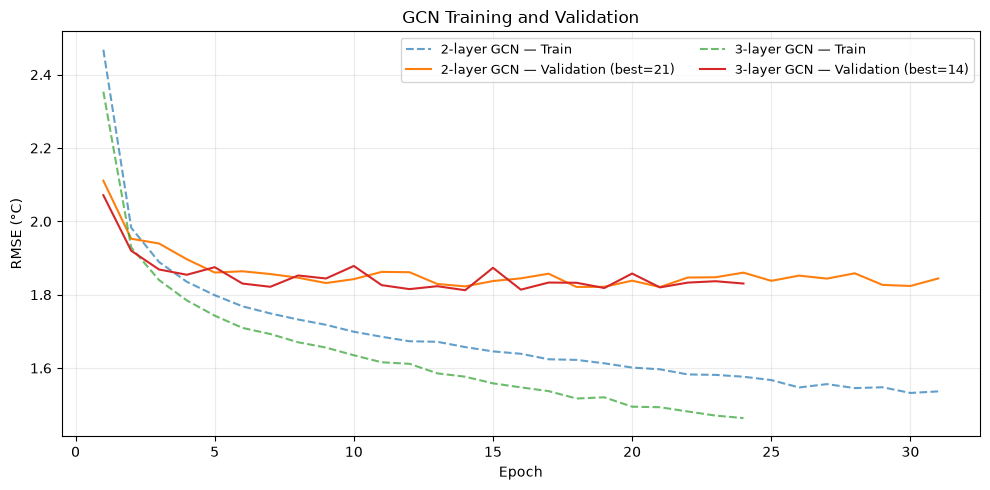

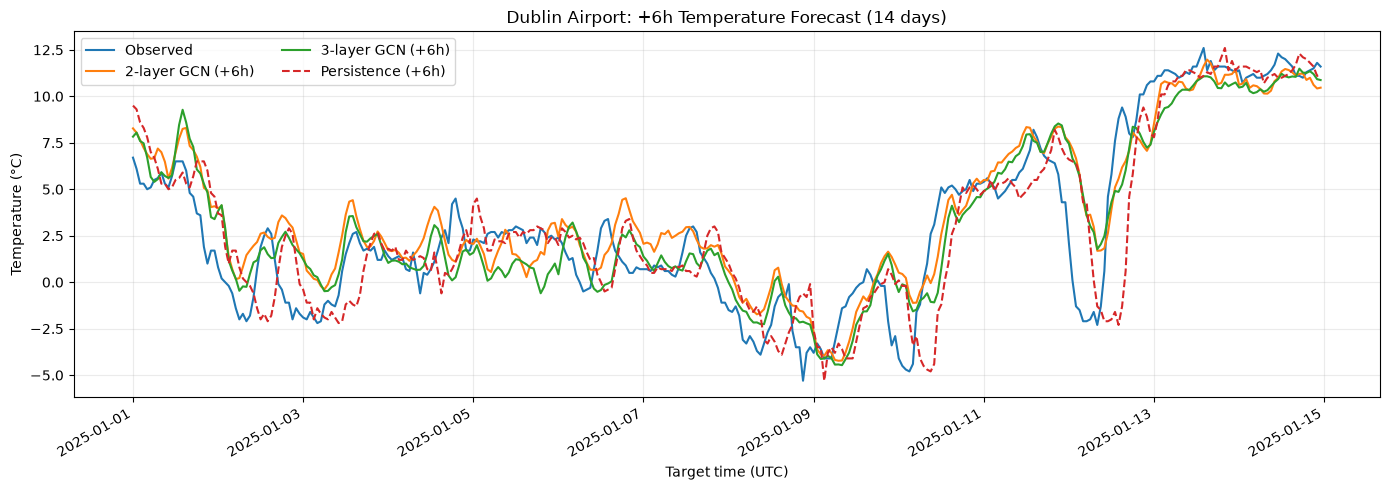

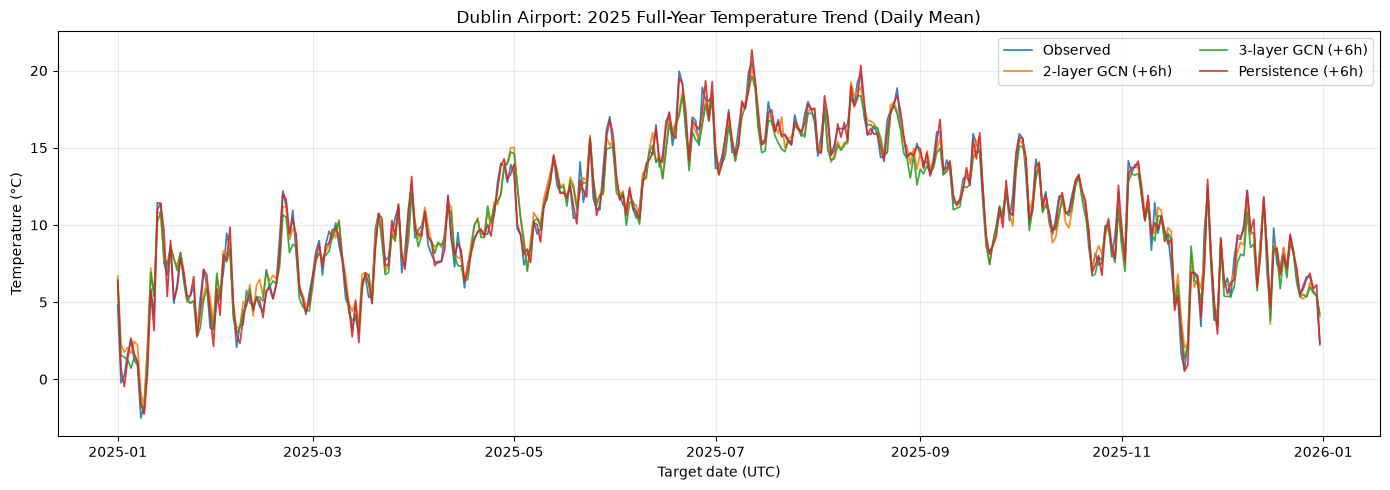

In [9]:
# 1. Training curves for both GCNs (RMSE in original Celsius units)
fig, ax = plt.subplots(figsize=(10, 5))
for label, history, best_epoch in (
    ("2-layer GCN", history_2, best_epoch_2),
    ("3-layer GCN", history_3, best_epoch_3),
):
    epochs = np.arange(1, len(history["train_mse"]) + 1)
    train_rmse = np.sqrt(history["train_mse"]) * y_std
    val_rmse = np.sqrt(history["val_mse"]) * y_std
    ax.plot(epochs, train_rmse, linestyle="--", alpha=0.7, label=f"{label} — Train")
    ax.plot(epochs, val_rmse, label=f"{label} — Validation (best={best_epoch})")
ax.set(title="GCN Training and Validation", xlabel="Epoch", ylabel="RMSE (°C)")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(DATA_DIR / "gcn_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Same target timestamps for observed / persistence / both GCN forecasts
#    A 14-day hourly view shows the lag and timing of local temperature changes.
PLOT_START = "2025-01-01"
PLOT_DAYS = 14
start = pd.Timestamp(PLOT_START, tz="UTC")
end = start + pd.Timedelta(days=PLOT_DAYS)
window = (forecast_df["date"] >= start) & (forecast_df["date"] < end)
assert window.any(), "Selected forecast plot window is outside the test set"

fig, ax = plt.subplots(figsize=(14, 5))
for col, label, style in (
    ("observed", "Observed", "-"),
    ("gcn_2layer", "2-layer GCN (+6h)", "-"),
    ("gcn_3layer", "3-layer GCN (+6h)", "-"),
    ("persistence", "Persistence (+6h)", "--"),
):
    ax.plot(forecast_df.loc[window, "date"], forecast_df.loc[window, col],
            label=label, linestyle=style, linewidth=1.5)
ax.set(title=f"Dublin Airport: +{HORIZON}h Temperature Forecast ({PLOT_DAYS} days)",
       xlabel="Target time (UTC)", ylabel="Temperature (°C)")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(DATA_DIR / "gcn_forecast_14days.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Full-year trend: daily averages of the same hourly forecast targets
#    Daily averaging is for visualisation only; evaluation above uses all hourly values.
daily = forecast_df.set_index("date").resample("D").mean()
fig, ax = plt.subplots(figsize=(14, 5))
for col, label in (
    ("observed", "Observed"),
    ("gcn_2layer", "2-layer GCN (+6h)"),
    ("gcn_3layer", "3-layer GCN (+6h)"),
    ("persistence", "Persistence (+6h)"),
):
    ax.plot(daily.index, daily[col], label=label, alpha=0.9, linewidth=1.25)
ax.set(title="Dublin Airport: 2025 Full-Year Temperature Trend (Daily Mean)",
       xlabel="Target date (UTC)", ylabel="Temperature (°C)")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.savefig(DATA_DIR / "gcn_forecast_2025_daily.png", dpi=300, bbox_inches="tight")
plt.show()
